# Where does the final model fail?

Loads the final model (`best_1024_60ep.pt`: 18,000 pages, 1024 px, 60 epochs),
runs it on the **500 validation pages**, and sorts every mistake into one of three kinds:

| Mistake | Meaning |
|---|---|
| **Missed** | A real table with no matching prediction |
| **Extra** | A prediction that matches no real table |
| **Loose** | Matched, but the box overlaps the real table by less than 75% |

We use validation pages, not test pages, so the test set stays untouched.

Runs on CPU in a few minutes. No internet needed after the install.

## 1. Install

In [1]:
# CPU-only PyTorch is much smaller to download. Skip this cell if ultralytics is installed.
%pip install -q torch torchvision --index-url https://download.pytorch.org/whl/cpu
%pip install -q "ultralytics==8.3.221" pandas matplotlib


[notice] A new release of pip is available: 23.2.1 -> 26.2.2
[notice] To update, run: /tmp/claude-1000/-home-beka-Desktop-upgaming/59862bc9-579f-431c-8f56-ad3d55c070c7/scratchpad/venv/bin/python3 -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.2.1 -> 26.2.2
[notice] To update, run: /tmp/claude-1000/-home-beka-Desktop-upgaming/59862bc9-579f-431c-8f56-ad3d55c070c7/scratchpad/venv/bin/python3 -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


## 2. Imports and settings

In [2]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.patches import Rectangle
from PIL import Image
from ultralytics import YOLO

MODEL = Path("../models/best_1024_60ep.pt")
IMAGES = Path("../data/validation_pages/images")
LABELS = Path("../data/validation_pages/labels")
PAGE_INFO = Path("../results/01_scaling_study/selected_pages.json")  # Document type of each page.

IMGSZ = 1024       # Same size the model was trained at.
CONFIDENCE = 0.25  # Ignore predictions less confident than this.
MATCH_IOU = 0.50   # Overlap needed to count a table as found.
TIGHT_IOU = 0.75   # Below this, a found table's box is "loose".
PAGES_TO_SHOW = 4  # Pages shown per mistake type.

model = YOLO(str(MODEL))
pages = sorted(IMAGES.glob("*.png"))
print(f"Model: {MODEL.name} | validation pages: {len(pages)}")

Model: best_1024_60ep.pt | validation pages: 500


## 3. How a prediction is matched to a real table

**IoU** (intersection over union) is the overlap between two boxes: 1.0 means
identical, 0 means not touching.

Predictions are matched most-confident first. Each one claims the real table it
overlaps most, as long as the IoU is at least 0.5 and no other prediction has
already claimed that table.

In [3]:
def iou(boxes, box):
    # Overlap of one box against many. Boxes are [x1, y1, x2, y2] in pixels.
    top_left = np.maximum(boxes[:, :2], box[:2])
    bottom_right = np.minimum(boxes[:, 2:], box[2:])
    overlap = np.clip(bottom_right - top_left, 0, None).prod(axis=1)
    area = (boxes[:, 2:] - boxes[:, :2]).prod(axis=1)
    union = area + (box[2:] - box[:2]).prod() - overlap
    return overlap / union


def real_tables(page, width, height):
    # The label file stores "class center_x center_y width height", divided by page size.
    text = (LABELS / f"{page.stem}.txt").read_text().split()
    labels = np.array(text, dtype=float).reshape(-1, 5)
    centers = labels[:, 1:3] * [width, height]
    sizes = labels[:, 3:5] * [width, height]
    return np.hstack([centers - sizes / 2, centers + sizes / 2])


def match(truth, predicted, confidence):
    found = np.zeros(len(truth), dtype=bool)    # For each real table: was it found?
    overlap = np.zeros(len(predicted))          # For each prediction: IoU with its match (0 = none).

    for i in np.argsort(-confidence):
        if len(truth) == 0:
            break
        scores = iou(truth, predicted[i])
        scores[found] = 0  # A real table can only be claimed once.
        best = scores.argmax()
        if scores[best] >= MATCH_IOU:
            found[best] = True
            overlap[i] = scores[best]
    return found, overlap

## 4. Run the model on every validation page

In [4]:
domain = {r["page_hash"]: r["domain"] for r in json.loads(PAGE_INFO.read_text())["validation"]}

results = []
for number, page in enumerate(pages, start=1):
    prediction = model.predict(page, imgsz=IMGSZ, conf=CONFIDENCE, verbose=False)[0]
    height, width = prediction.orig_shape

    truth = real_tables(page, width, height)
    predicted = prediction.boxes.xyxy.numpy()
    confidence = prediction.boxes.conf.numpy()
    found, overlap = match(truth, predicted, confidence)

    results.append({
        "page": page.stem,
        "domain": domain[page.stem],
        "real": len(truth),
        "predicted": len(predicted),
        "missed": int((~found).sum()),
        "extra": int((overlap == 0).sum()),
        "loose": int(((overlap > 0) & (overlap < TIGHT_IOU)).sum()),
        "worst_iou": overlap[overlap > 0].min() if (overlap > 0).any() else np.nan,
        # Kept for drawing later.
        "truth_boxes": truth, "found": found,
        "pred_boxes": predicted, "confidence": confidence, "overlap": overlap,
    })
    if number % 100 == 0:
        print(f"{number}/{len(pages)} pages done")

results = pd.DataFrame(results)

100/500 pages done


200/500 pages done


300/500 pages done


400/500 pages done


500/500 pages done


## 5. Summary

In [5]:
real = results["real"].sum()
missed = results["missed"].sum()
extra = results["extra"].sum()
loose = results["loose"].sum()

print(f"Real tables:      {real}")
print(f"Found:            {real - missed}  ({(real - missed) / real:.0%})")
print(f"Missed:           {missed}")
print(f"Extra boxes:      {extra}  (on {(results['extra'] > 0).sum()} pages)")
print(f"Loose boxes:      {loose}  (found, but IoU below {TIGHT_IOU})")
print(f"Pages with no mistake: {(results[['missed', 'extra', 'loose']].sum(axis=1) == 0).sum()} of {len(results)}")

Real tables:      180
Found:            153  (85%)
Missed:           27
Extra boxes:      23  (on 19 pages)
Loose boxes:      8  (found, but IoU below 0.75)
Pages with no mistake: 466 of 500


### Which document types cause the mistakes?

If the mistakes cluster in one or two document types, that is a concrete,
fixable finding: collect more pages of that kind.

In [6]:
by_type = results.groupby("domain")[["real", "missed", "extra", "loose"]].sum()
by_type.insert(0, "pages", results.groupby("domain").size())
by_type["missed %"] = (100 * by_type["missed"] / by_type["real"]).round(0)
by_type.sort_values("missed", ascending=False)

,pages,real,missed,extra,loose,missed %
domain,,,,,,
financial_reports,114,87,11,14,5,13.0
government_tenders,47,29,11,4,1,38.0
patents,93,40,5,3,1,12.0
laws_and_regulations,45,7,0,1,0,0.0
manuals,9,2,0,1,1,0.0
scientific_articles,192,15,0,0,0,0.0


## 6. The worst pages

**Left:** the real tables (green = found, red = missed).
**Right:** what the model predicted (blue = tight, orange = loose, red = matches no real table).

In [7]:
def show(row):
    with Image.open(IMAGES / f"{row['page']}.png") as opened:
        image = opened.convert("RGB")

    fig, (left, right) = plt.subplots(1, 2, figsize=(14, 8))
    for axis in (left, right):
        axis.imshow(image)
        axis.axis("off")

    for box, was_found in zip(row["truth_boxes"], row["found"]):
        draw_box(left, box, "limegreen" if was_found else "red")

    for box, score, overlap in zip(row["pred_boxes"], row["confidence"], row["overlap"]):
        colour = "red" if overlap == 0 else "orange" if overlap < TIGHT_IOU else "dodgerblue"
        caption = f"conf {score:.2f}, IoU {overlap:.2f}" if overlap else f"conf {score:.2f}, no match"
        draw_box(right, box, colour, caption)

    left.set_title(f"{row['real']} real table(s)")
    right.set_title(f"{row['predicted']} predicted")
    fig.suptitle(f"{row['domain']}  |  missed {row['missed']}, extra {row['extra']}, "
                 f"loose {row['loose']}  |  {row['page'][:16]}...")
    plt.tight_layout()
    plt.show()


def draw_box(axis, box, colour, caption=None):
    x1, y1, x2, y2 = box
    axis.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=colour, linewidth=2))
    if caption:
        axis.text(x1, max(y1 - 5, 0), caption, fontsize=9,
                  bbox=dict(facecolor="white", alpha=0.85, edgecolor=colour))

### Missed tables

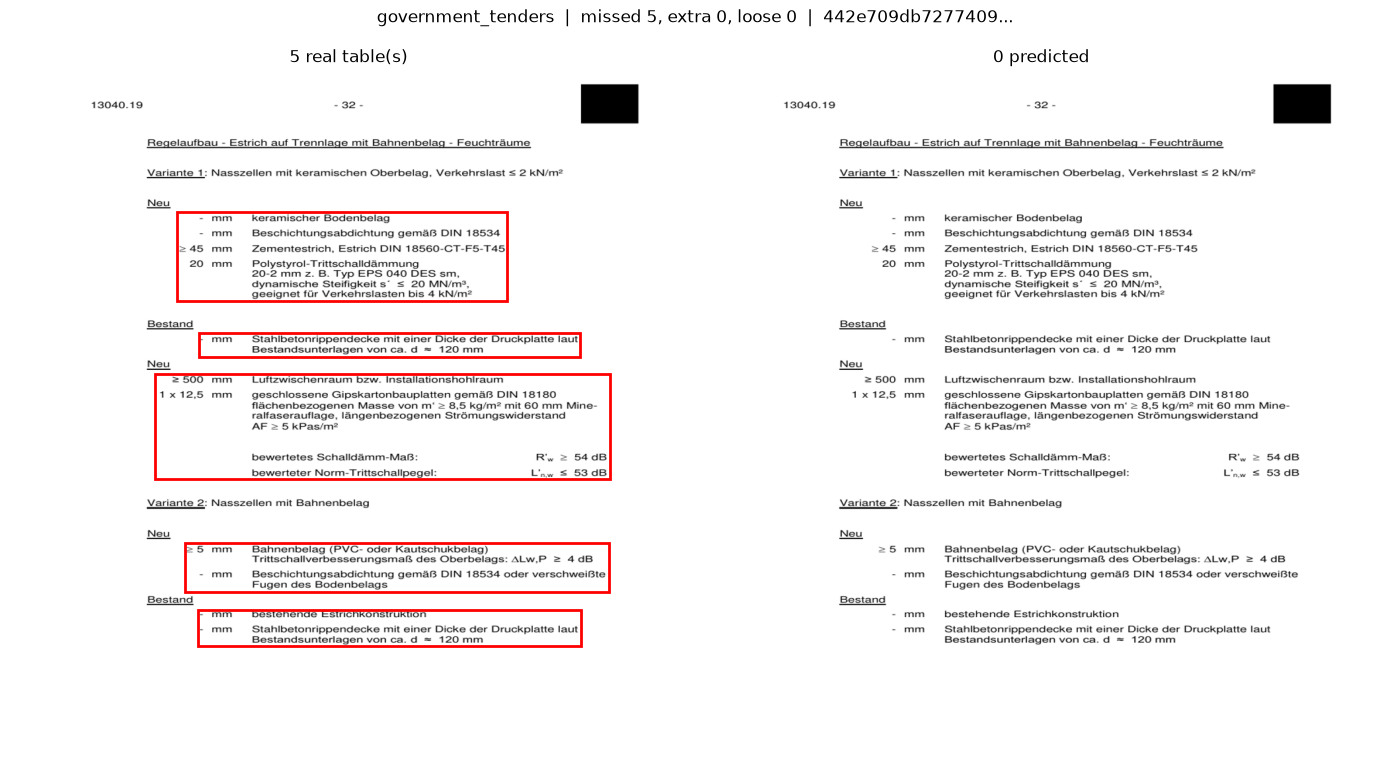

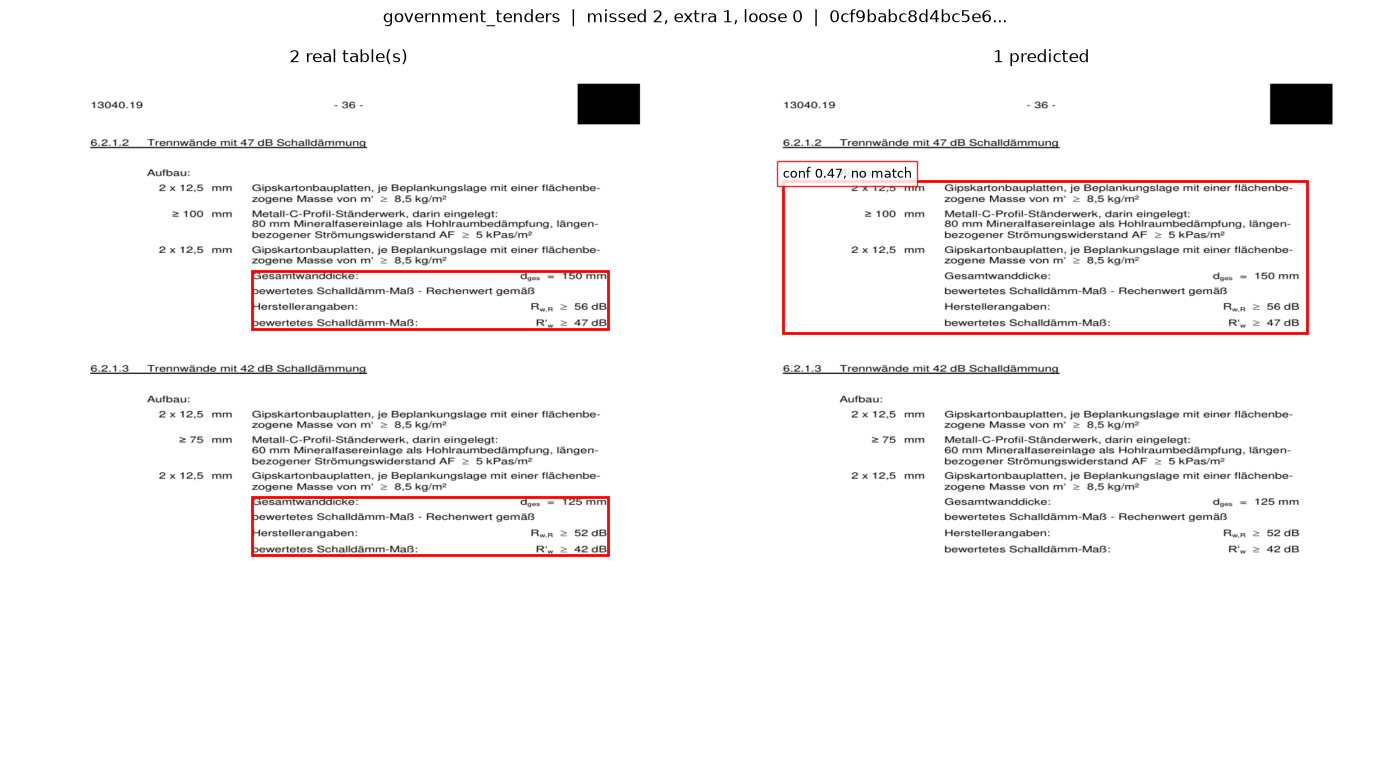

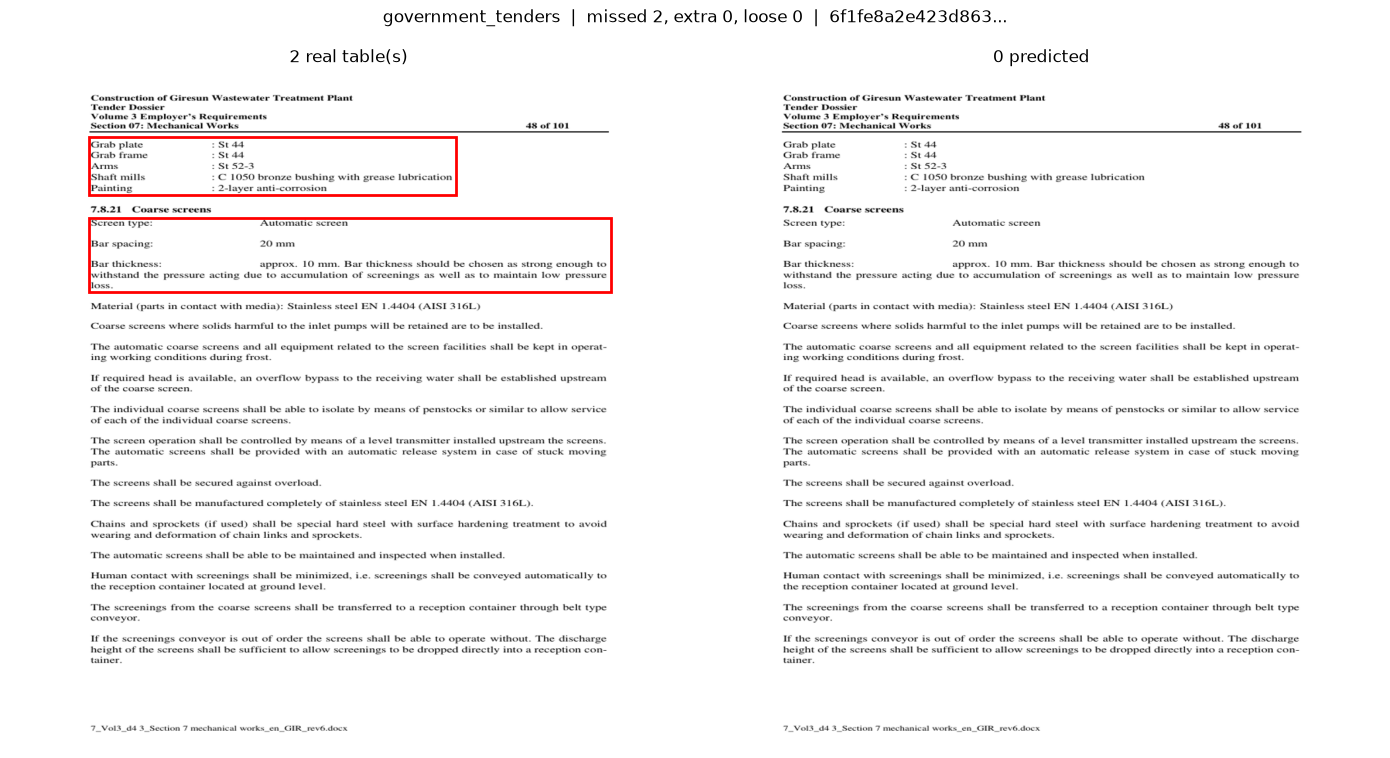

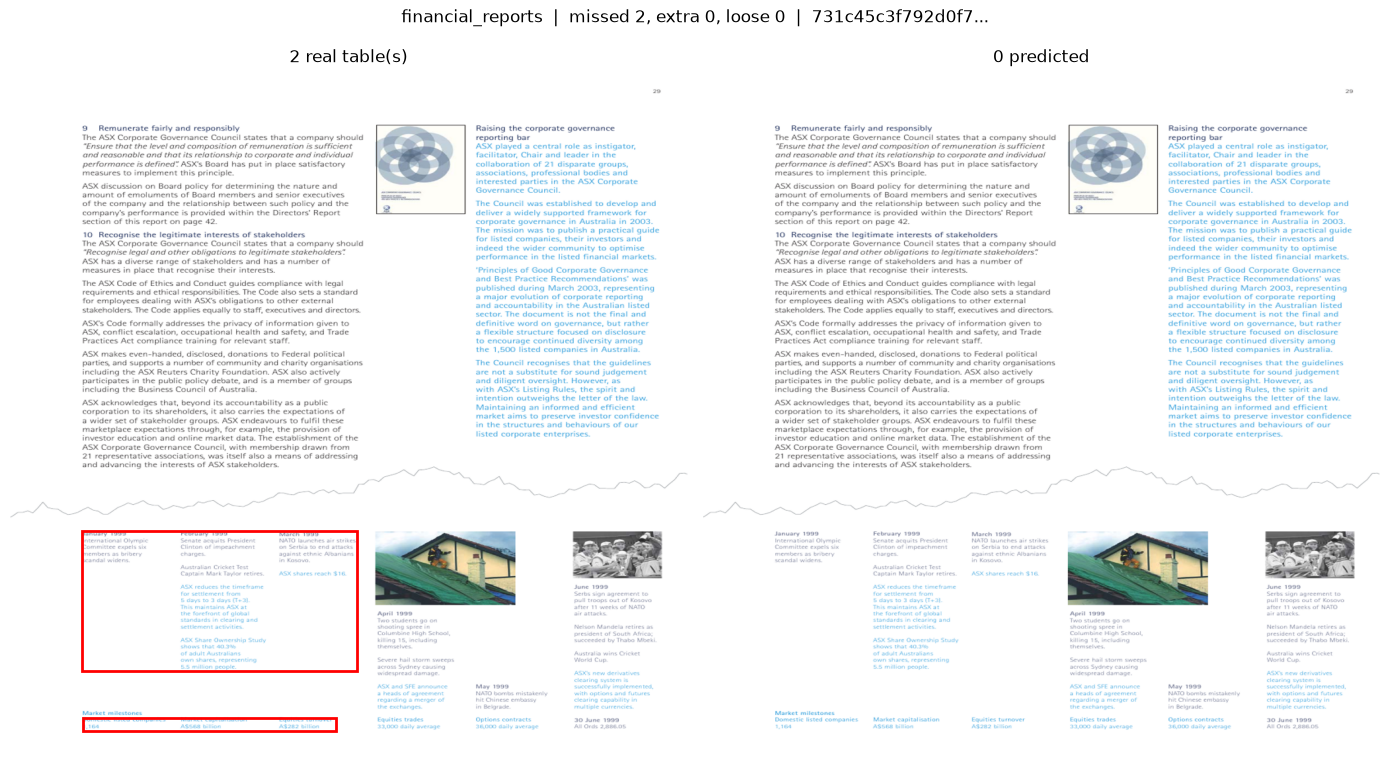

In [8]:
for _, row in results[results["missed"] > 0].nlargest(PAGES_TO_SHOW, "missed").iterrows():
    show(row)

### Extra boxes (the model saw a table that isn't there)

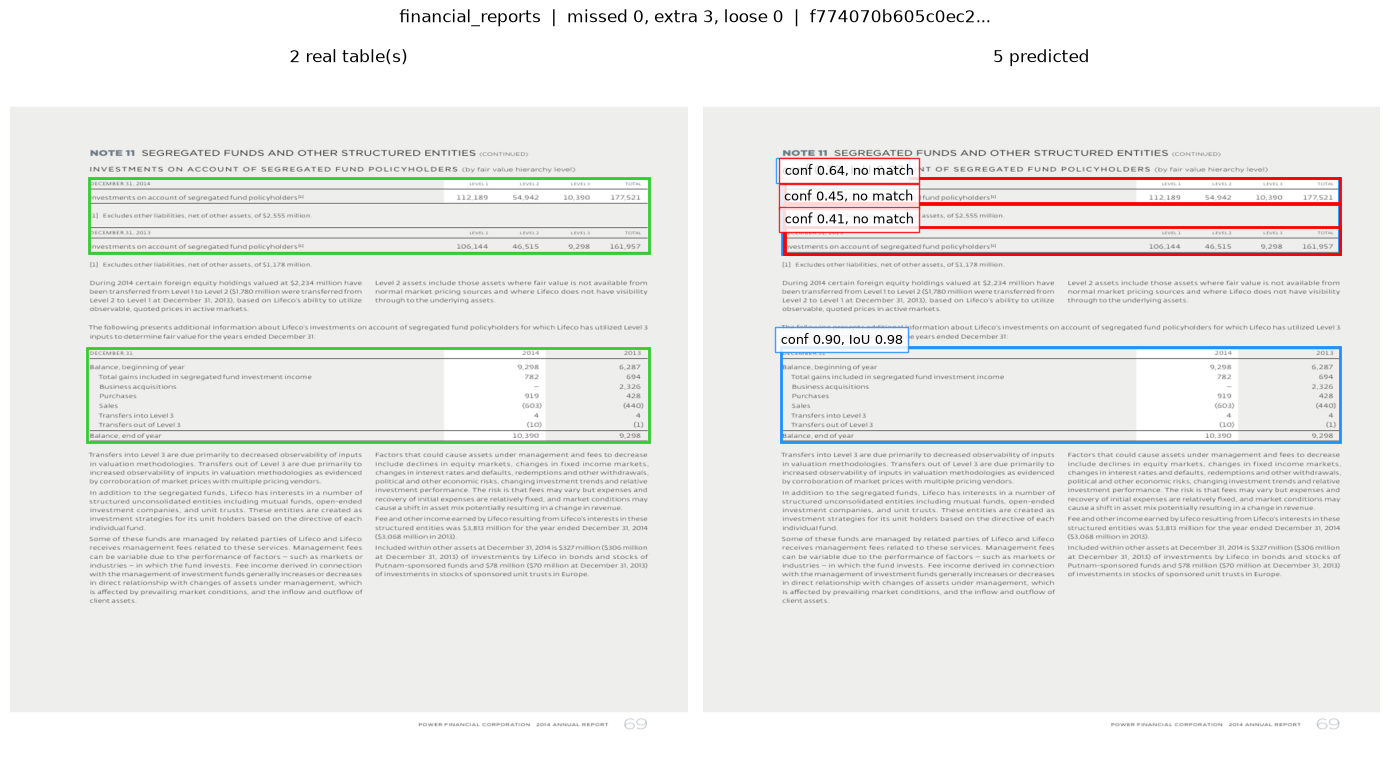

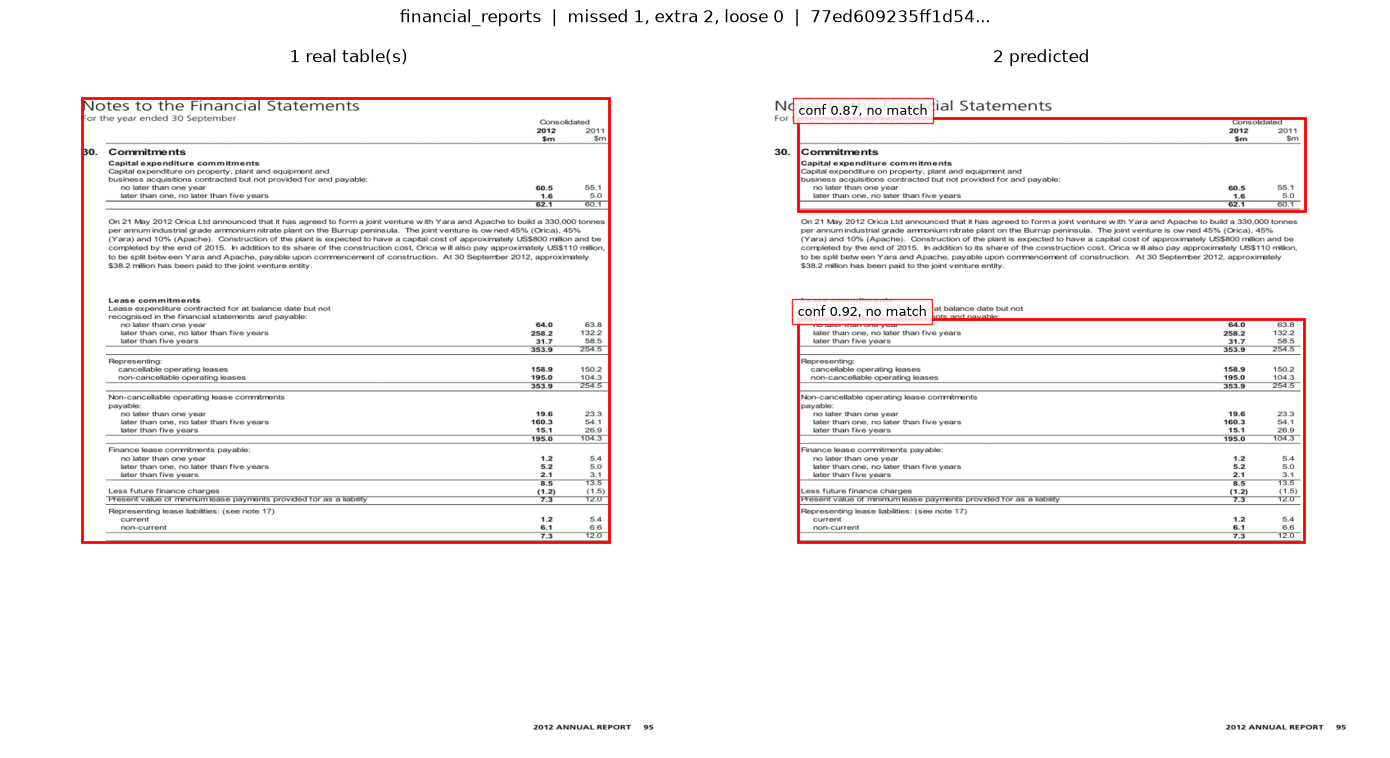

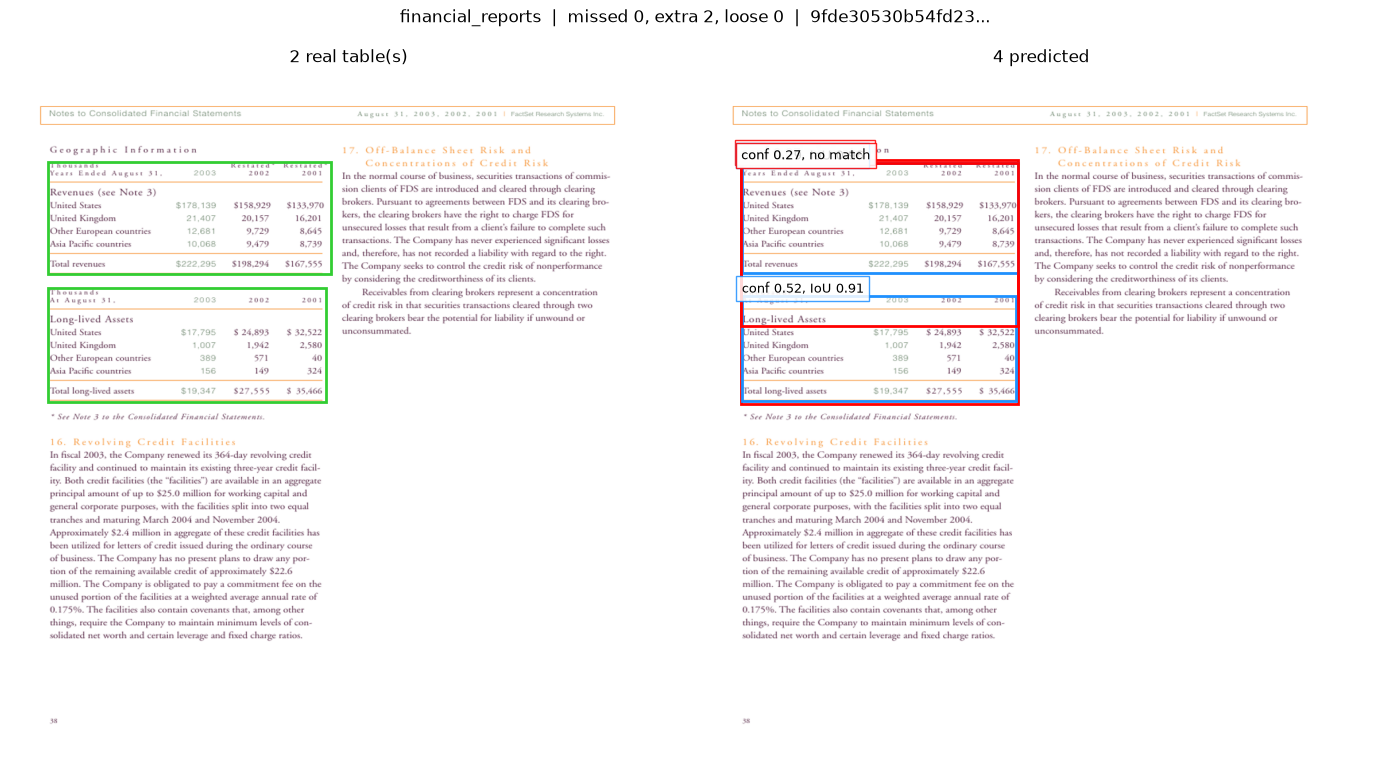

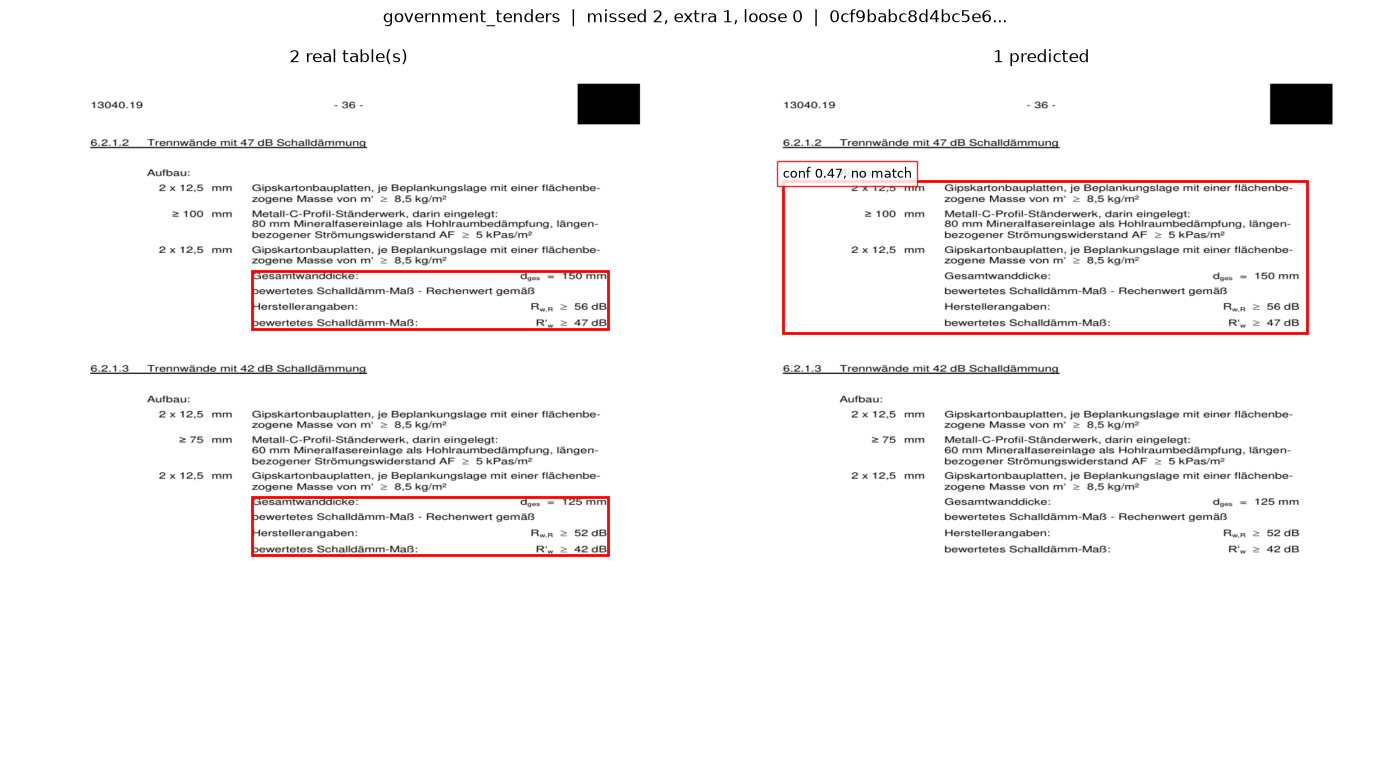

In [9]:
for _, row in results[results["extra"] > 0].nlargest(PAGES_TO_SHOW, "extra").iterrows():
    show(row)

### Loose boxes (found, but the box fits badly)

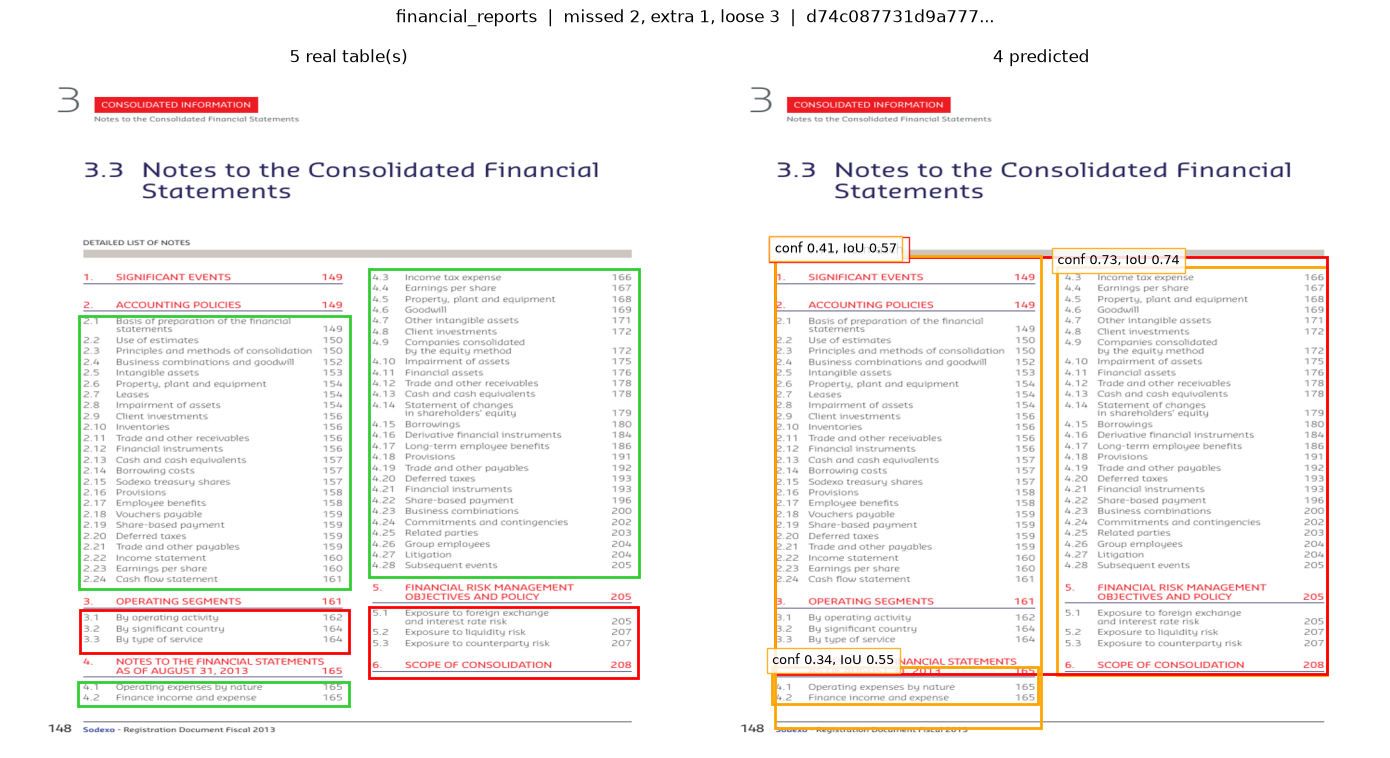

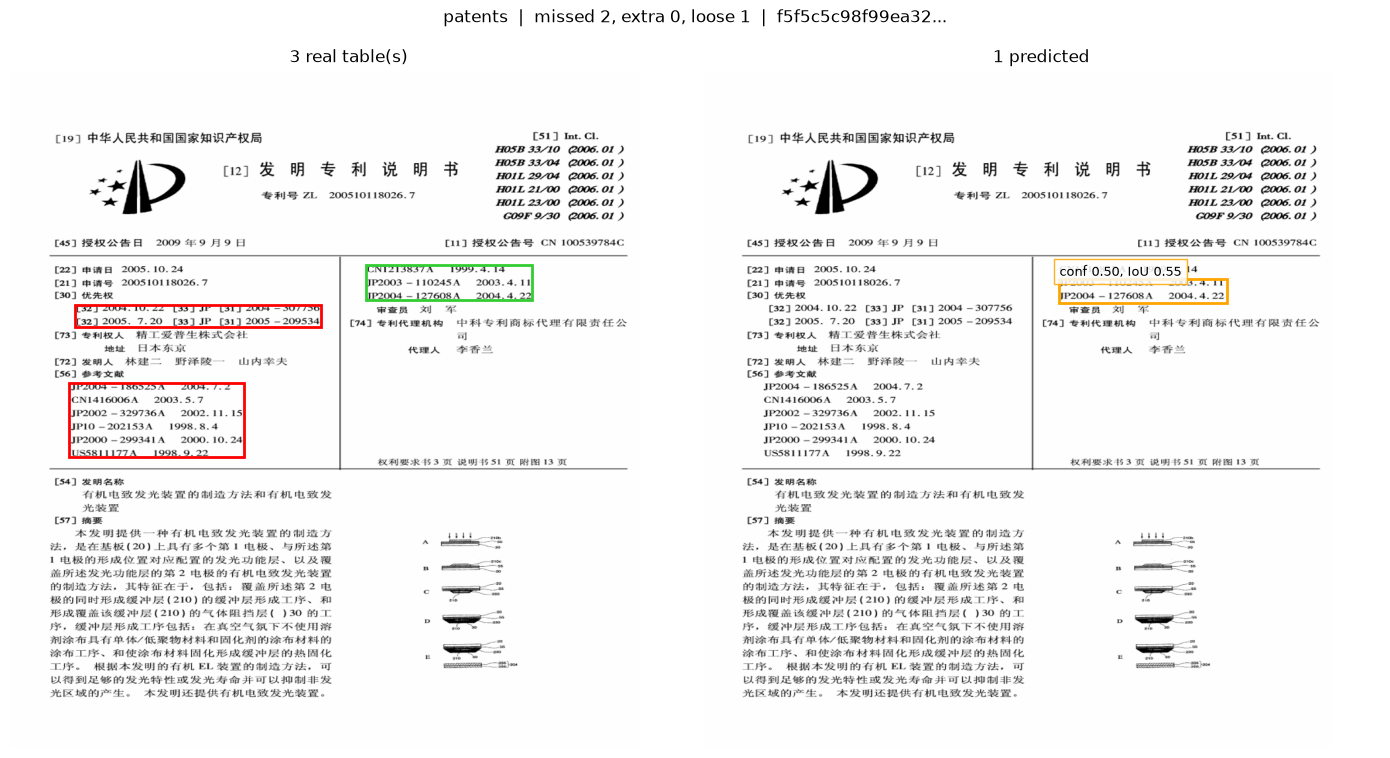

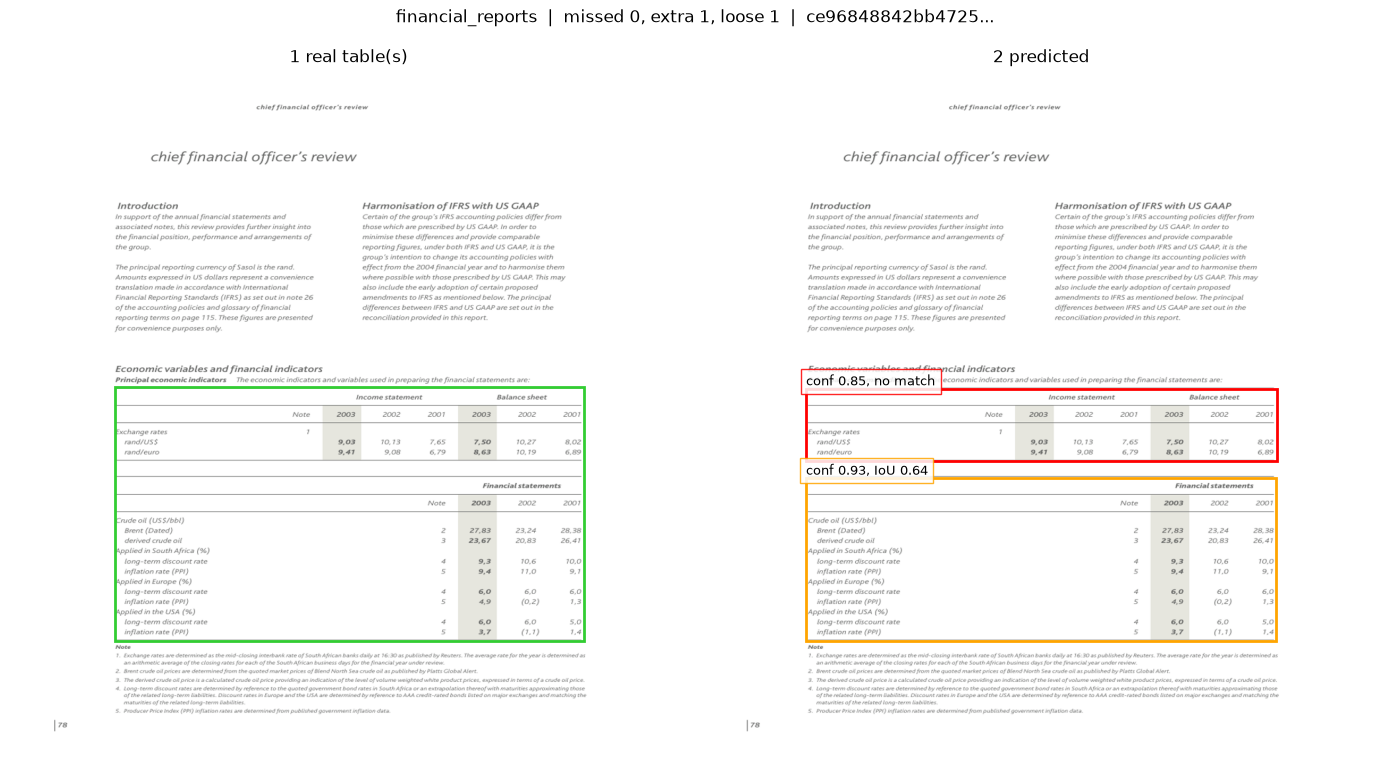

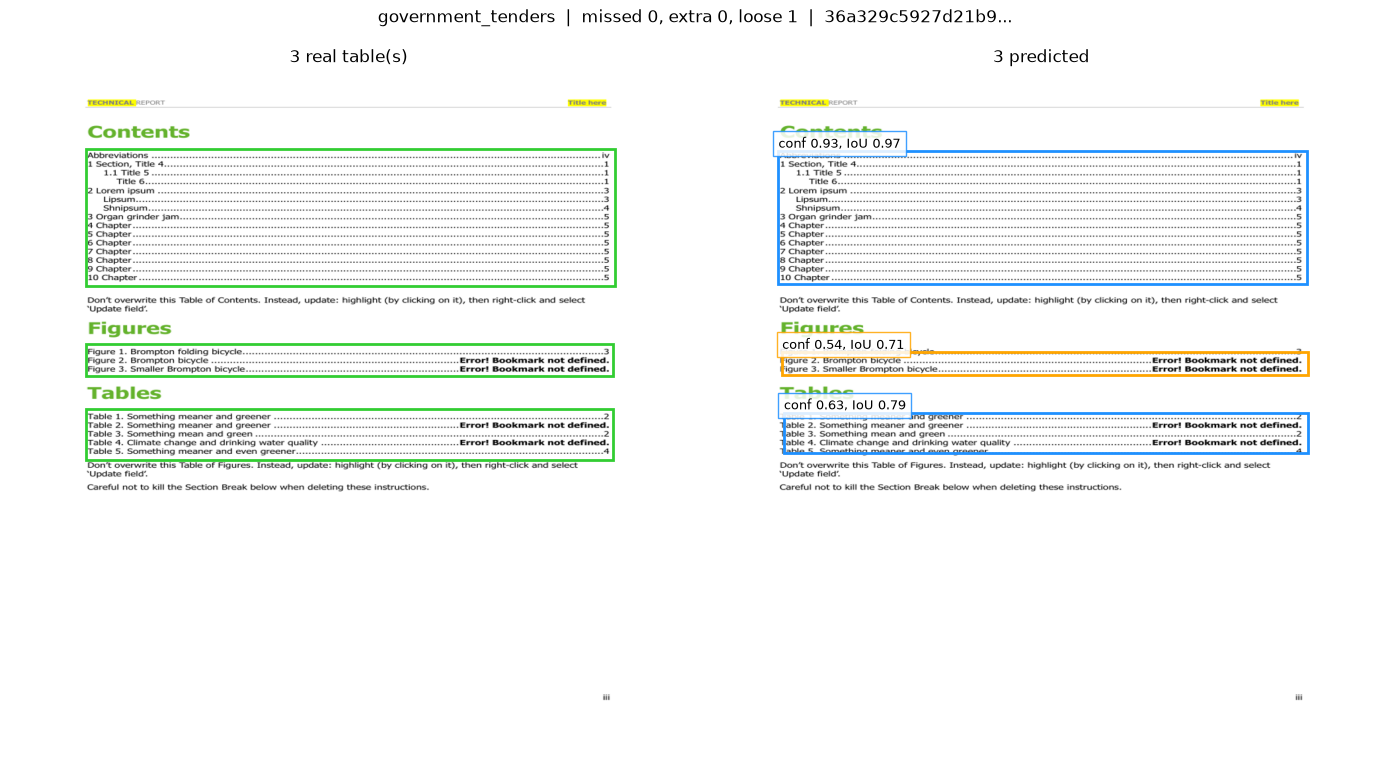

In [10]:
for _, row in results[results["loose"] > 0].nsmallest(PAGES_TO_SHOW, "worst_iou").iterrows():
    show(row)

## 7. Look at any page yourself

Every page with a mistake, worst first. Copy a page id into the cell below to draw it.

In [11]:
mistakes = results[results[["missed", "extra", "loose"]].sum(axis=1) > 0]
mistakes = mistakes.sort_values(["missed", "extra", "loose"], ascending=False)
display(mistakes[["page", "domain", "real", "predicted", "missed", "extra", "loose", "worst_iou"]])

,page,domain,real,predicted,missed,extra,loose,worst_iou
117,442e709db727740908de041c212d9655bdb296d30537ac...,government_tenders,5,0,5,0,0,NaN
410,d74c087731d9a77751dce528ade5dedbebfb956070861b...,financial_reports,5,4,2,1,3,0.549724
15,0cf9babc8d4bc5e6b69850ee3a7c5028846157702fd83c...,government_tenders,2,1,2,1,0,NaN
475,f5f5c5c98f99ea32375988bd8d34d3ef98e8a1c42c9b38...,patents,3,1,2,0,1,0.550089
194,6f1fe8a2e423d86379c0a08bf5999f27633ca4f8d209e1...,government_tenders,2,0,2,0,0,NaN
206,731c45c3f792d0f7cb6dba6fb8865d011755c336ac5787...,financial_reports,2,0,2,0,0,NaN
216,77ed609235ff1d5463c1ced1a8a589993834dd6183d067...,financial_reports,1,2,1,2,0,NaN
231,7e1f983745ab74616369ffe54e8bbe85499cd69340b602...,patents,1,1,1,1,0,NaN
311,ad7c3029b69a42b8d25429fabd1cc7d01de0ba817d61cd...,financial_reports,2,2,1,1,0,0.983046
454,edbacd53c977c1becc7a180dc53768535c896e750bb7bf...,financial_reports,2,2,1,1,0,0.880948


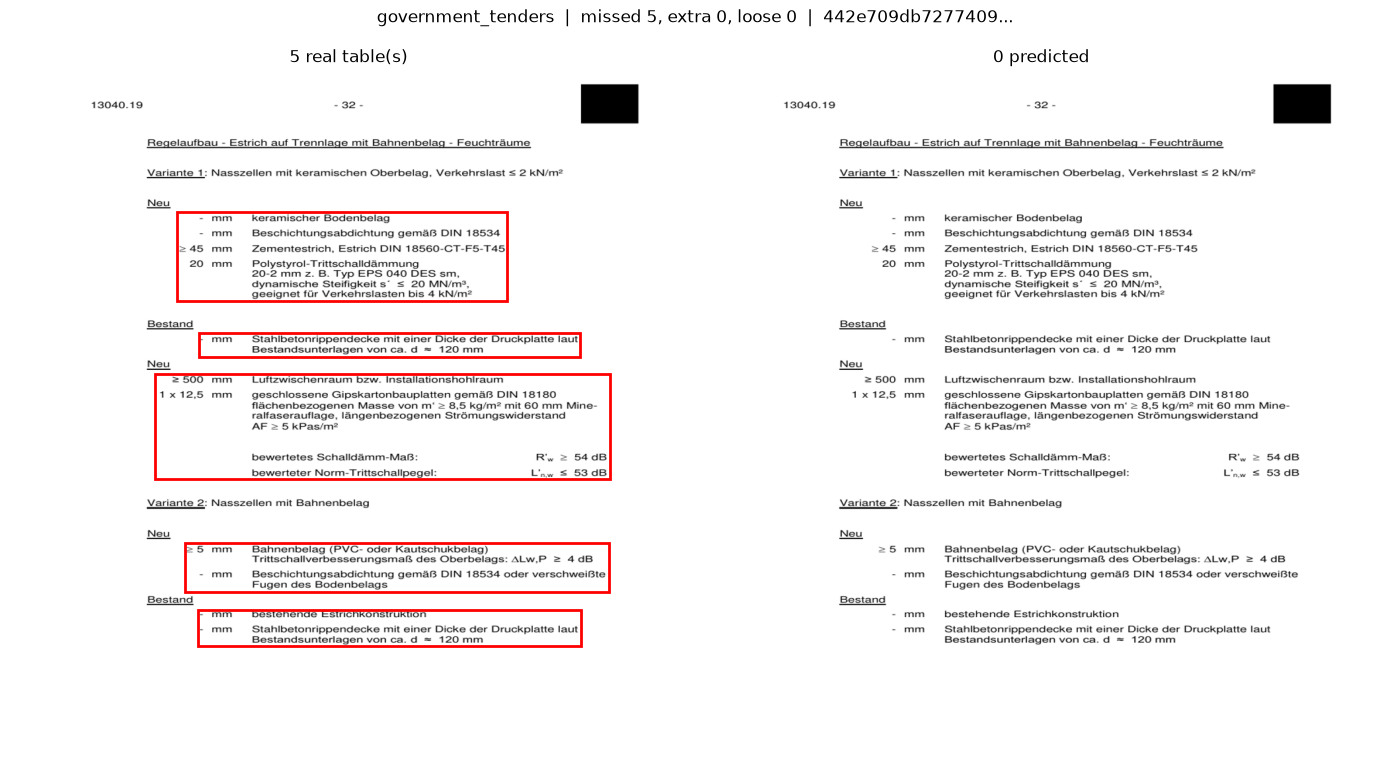

In [12]:
PAGE = mistakes["page"].iloc[0]  # Or paste a page id here, e.g. PAGE = "29a8363b..."
show(results[results["page"] == PAGE].iloc[0])